In [1]:
# Data Import from Dynamic Excel Model

import pandas as pd
import numpy as np
import xlwings as xw

wb = xw.Book(r"C:\Users\POU\OneDrive - Avertim\DynamicModel\Dynamic_Carbon_Exposure_Model.xlsx")
control = wb.sheets["ControlPanel"]
dcf = wb.sheets["NPV_Output"]
ds = wb.sheets["DataSources"]

regimes = ["status_quo", "fit_for_55", "accelerated"]
percentiles = ["P25", "P50", "P75"]
ignore_labels = {"Energy", "Transport", "Life Sciences"}

carbon_cost_blocks = []
results = []

for regime in regimes:
    control["C6"].value = regime

    for pct in percentiles:
        control["C7"].value = pct

        wb.app.calculate()

        # Read Data Block
        data = dcf["B10:N41"].options(pd.DataFrame, header=False).value
        data = data.reset_index()
        data.columns = ["Label", "2026", "2027", "2028", "2029", "2030", "2031", "2032", "2033", "2034", "2035", "C11", "NPV"]

        # Future Carbon Costs Data Cleaning
        year_cols = ["2026", "2027", "2028", "2029", "2030", "2031", "2032", "2033", "2034", "2035"]
        years = list(range(2026,2035))

        # Create Sector Column from Headers
        data["Sector"] = np.where(
            data["Label"].isin(ignore_labels),
            data["Label"],
            np.nan
        )

        # Forward-fill sector to firms
        data["Sector"] = data["Sector"].ffill()

        # Keep only firm rows
        data = data[
            (~data["Label"].isin(ignore_labels)) &
            (data["Label"].notna()) &
            (data["NPV"].notna())
            ]
        
        # Rename
        data["Firm"] = data["Label"]
        data["Regime"] = regime
        data["Percentile"] = pct

        final_block = data[["Firm", "Sector", "Regime", "Percentile", "NPV"]]

        results.append(final_block)

        carbon_long = data.melt(
            id_vars=["Firm", "Sector", "Regime", "Percentile"],
            value_vars=year_cols,
            var_name="Year",
            value_name="CarbonCost"
        )

        carbon_cost_blocks.append(carbon_long)

df_carbon_costs = pd.concat(carbon_cost_blocks, ignore_index=True)
df_npvs = pd.concat(results, ignore_index = True)

# SBTI Compliance
sbti = ds["B18:D42"].options(
    pd.DataFrame,
    header=True,
    index=False
).value

df_npvs = df_npvs.merge(sbti, on="Firm", how="left")
df_carbon_costs = df_carbon_costs.merge(sbti, on="Firm", how="left")

print("All different scenarios and percentiles have been run through in the ControlPanel sheet, and its corresponding NPV output has been all combined in the df_npvs DataFrame, whilst the future carbon costs can be found in df_carbon_costs.")
print(df_npvs.head(10))
print(df_npvs.tail(10))
print(df_npvs.groupby(["Regime", "Percentile"]).size())

print(df_carbon_costs.head(10))
print(df_carbon_costs.tail(10))
print(df_carbon_costs.groupby(["Regime", "Percentile"]).size())

All different scenarios and percentiles have been run through in the ControlPanel sheet, and its corresponding NPV output has been all combined in the df_npvs DataFrame, whilst the future carbon costs can be found in df_carbon_costs.
                Firm         Sector      Regime Percentile           NPV  \
0    AstraZeneca PLC  Life Sciences  status_quo        P25  2.972466e+07   
1           Bayer AG  Life Sciences  status_quo        P25  1.006316e+07   
2        Novartis AG  Life Sciences  status_quo        P25  3.417110e+07   
3   Roche Holding AG  Life Sciences  status_quo        P25  3.427298e+07   
4             Sanofi  Life Sciences  status_quo        P25  1.710419e+07   
5             UCB SA  Life Sciences  status_quo        P25  2.658759e+06   
6            GSK plc  Life Sciences  status_quo        P25  1.366570e+07   
7       BioNTech SE   Life Sciences  status_quo        P25  5.687021e+05   
8             Pfizer  Life Sciences  status_quo        P25  3.689173e+07   
9  Joh

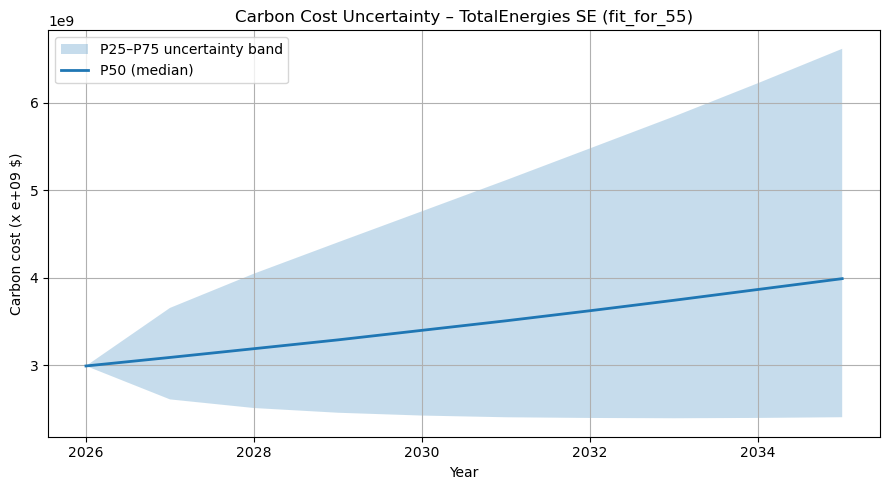

In [2]:
# Carbon Costs Vizualisation
# Firm Specific

import matplotlib.pyplot as plt

# USER SELECTION
selected_firm = "TotalEnergies SE"          # change as needed
selected_regime = "fit_for_55"    # status_quo / fit_for_55 / accelerated

# FILTER DATA
df_plot = df_carbon_costs[
    (df_carbon_costs["Firm"] == selected_firm) &
    (df_carbon_costs["Regime"] == selected_regime)
].copy()

# Ensure Year is numeric
df_plot["Year"] = df_plot["Year"].astype(int)

# Pivot percentiles into columns
df_wide = df_plot.pivot_table(
    index="Year",
    columns="Percentile",
    values="CarbonCost",
    aggfunc="mean"
).sort_index()

plt.figure(figsize=(9, 5))

# Shaded uncertainty band
plt.fill_between(
    df_wide.index,
    df_wide["P25"],
    df_wide["P75"],
    alpha=0.25,
    label="P25–P75 uncertainty band"
)

# Median path
plt.plot(
    df_wide.index,
    df_wide["P50"],
    linewidth=2,
    label="P50 (median)"
)

# Labels & formatting
plt.title(f"Carbon Cost Uncertainty – {selected_firm} ({selected_regime})")
plt.xlabel("Year")
plt.ylabel("Carbon cost (x e+09 $)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

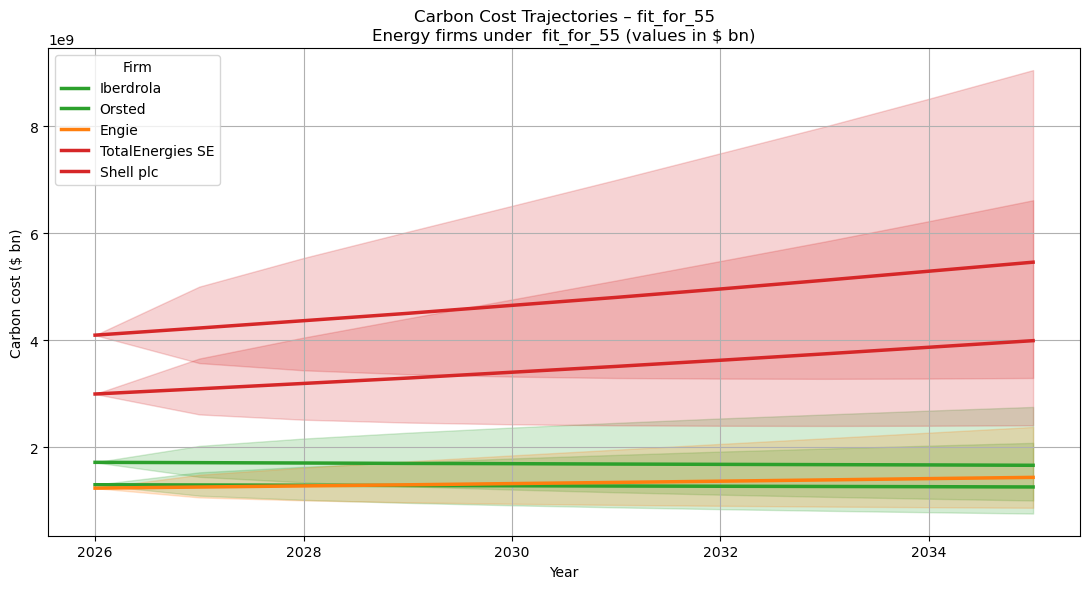

In [3]:
# Carbon Costs Vizualisation
# Sector Specific Firm-Level Comparison

import matplotlib.pyplot as plt

chosen_sector = "Energy"    # Energy / Transport / Life Sciences

firms = [
    "Iberdrola", "Orsted",  # green leader
    "Engie",       # intermediate
    "TotalEnergies SE", "Shell plc"       # no SBTi
]

selected_regime = "fit_for_55" # status_quo / fit_for_55 / accelerated

colors = {
    "Iberdrola": "tab:green",
    "Engie": "tab:orange",
    "Orsted": "tab:green",
    "TotalEnergies SE": "tab:red",
    "Shell plc": "tab:red"
}

plt.figure(figsize=(11, 6))

for firm in firms:

    df_plot = df_carbon_costs[
        (df_carbon_costs["Firm"] == firm) &
        (df_carbon_costs["Regime"] == selected_regime)
    ].copy()

    df_plot["Year"] = df_plot["Year"].astype(int)

    df_wide = df_plot.pivot_table(
        index="Year",
        columns="Percentile",
        values="CarbonCost",
        aggfunc="mean"
    ).sort_index()

    # Uncertainty band (light)
    plt.fill_between(
        df_wide.index,
        df_wide["P25"],
        df_wide["P75"],
        color=colors[firm],
        alpha=0.2
    )

    # Median line (focus)
    plt.plot(
        df_wide.index,
        df_wide["P50"],
        linewidth=2.5,
        color=colors[firm],
        label=firm
    )

plt.title(f"Carbon Cost Trajectories – {selected_regime}\n"
    f"{chosen_sector} firms under  {selected_regime} (values in $ bn)"
)
plt.xlabel("Year")
plt.ylabel("Carbon cost ($ bn)")
plt.legend(title="Firm")
plt.grid(True)

plt.tight_layout()
plt.show()

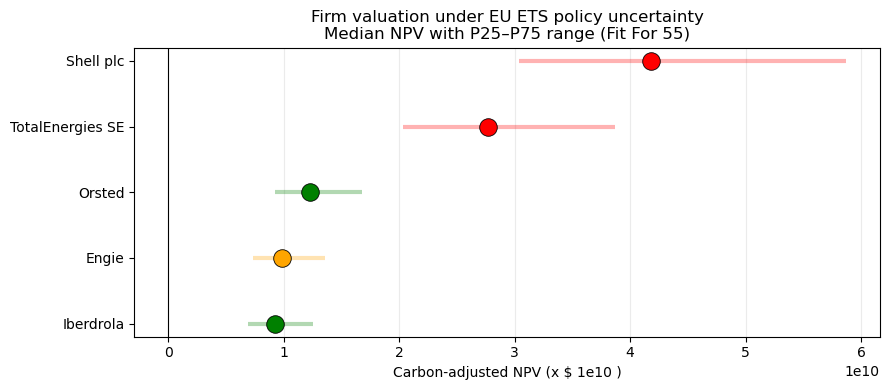

In [ ]:
# NPV Carbon Exposure Pricing Comparison
# User selections
firms = ["Iberdrola", "Engie", "Orsted", "TotalEnergies SE", "Shell plc"]
regime = "fit_for_55"

# Firm colors 
firm_colors = {
    "Iberdrola": "green",
    "Engie": "orange",
    "Orsted": "green",
    "TotalEnergies SE": "red",
    "Shell plc": "red"
}

# Filter data
df_plot = df_npvs[
    (df_npvs["Firm"].isin(firms)) &
    (df_npvs["Regime"] == regime) &
    (df_npvs["Percentile"].isin(["P25", "P50", "P75"]))
]

# Pivot to wide format
df_wide = df_plot.pivot(
    index="Firm",
    columns="Percentile",
    values="NPV"
).loc[firms]  # preserve firm order

# Build plot
fig, ax = plt.subplots(figsize=(9, 4))

y_pos = range(len(df_wide))

for i, firm in enumerate(df_wide.index):
    p25 = df_wide.loc[firm, "P25"]
    p50 = df_wide.loc[firm, "P50"]
    p75 = df_wide.loc[firm, "P75"]

    color = firm_colors.get(firm, "grey")

    # Uncertainty band 
    ax.hlines(
        y=i,
        xmin=p25,
        xmax=p75,
        color=color,
        alpha=0.3,
        linewidth=3
    )

    # Median circle 
    ax.scatter(
        p50,
        i,
        color=color,
        s=160,        # bigger = emphasis
        edgecolor="black",
        linewidth=0.6,
        zorder=4
    )

ax.set_yticks(list(y_pos))
ax.set_yticklabels(df_wide.index)

ax.set_xlabel("Carbon-adjusted NPV (x $ 1e10 )")
ax.set_title(
    f"Firm valuation under EU ETS policy uncertainty\n"
    f"Median NPV with P25–P75 range ({regime.replace('_', ' ').title()})"
)

ax.grid(axis="x", alpha=0.25)
ax.axvline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

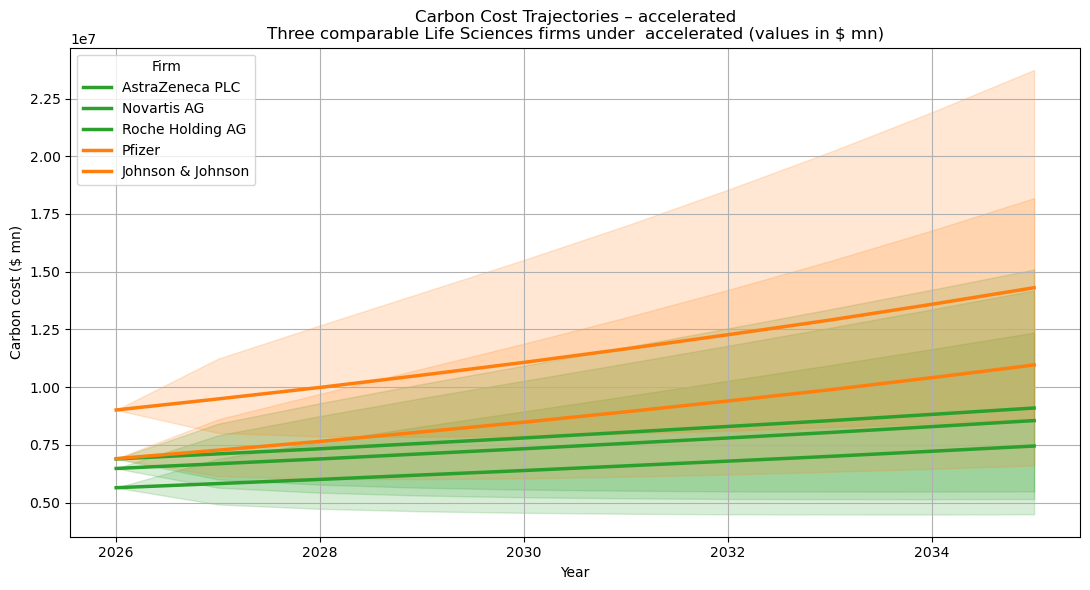

In [5]:
chosen_sector = "Life Sciences"    # Energy / Transport / Life Sciences

firms = [
    "AstraZeneca PLC", "Novartis AG", "Roche Holding AG",   # green leader
    "Pfizer", "Johnson & Johnson"       # intermediate
]

selected_regime = "accelerated" # status_quo / fit_for_55 / accelerated

colors = {
    "AstraZeneca PLC": "tab:green","Novartis AG": "tab:green", "Roche Holding AG": "tab:green",
    "Pfizer": "tab:orange", "Johnson & Johnson": "tab:orange"
}

plt.figure(figsize=(11, 6))

for firm in firms:

    df_plot = df_carbon_costs[
        (df_carbon_costs["Firm"] == firm) &
        (df_carbon_costs["Regime"] == selected_regime)
    ].copy()

    df_plot["Year"] = df_plot["Year"].astype(int)

    df_wide = df_plot.pivot_table(
        index="Year",
        columns="Percentile",
        values="CarbonCost",
        aggfunc="mean"
    ).sort_index()

    # Uncertainty band (light)
    plt.fill_between(
        df_wide.index,
        df_wide["P25"],
        df_wide["P75"],
        color=colors[firm],
        alpha=0.18
    )

    # Median line (focus)
    plt.plot(
        df_wide.index,
        df_wide["P50"],
        linewidth=2.5,
        color=colors[firm],
        label=firm
    )

plt.title(f"Carbon Cost Trajectories – {selected_regime}\n"
    f"Three comparable {chosen_sector} firms under  {selected_regime} (values in $ mn)"
)
plt.xlabel("Year")
plt.ylabel("Carbon cost ($ mn)")
plt.legend(title="Firm")
plt.grid(True)

plt.tight_layout()
plt.show()

C:\Users\POU\AppData\Local\Temp\ipykernel_8992\334301561.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot["Year"] = df_plot["Year"].astype(int)


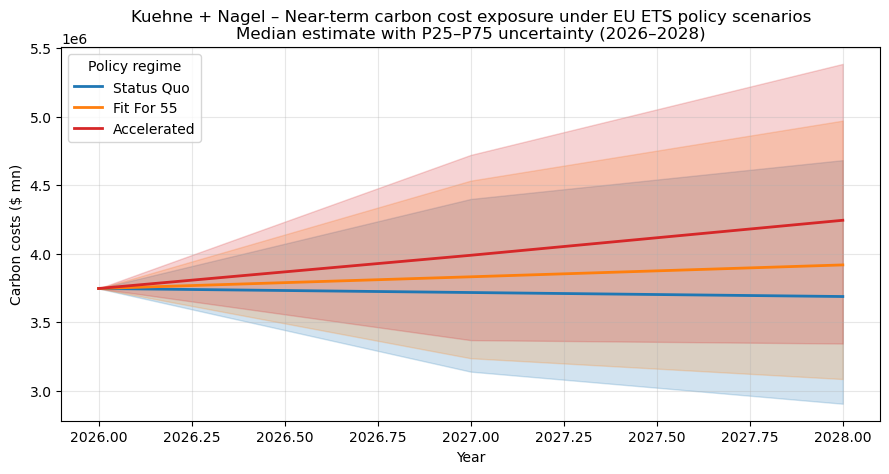

In [ ]:
# Firm Specific Carbon Cost Short-Term Uncertainty Range
# User selection
firm = "Kuehne + Nagel"
years = [2026, 2027, 2028]

regime_colors = {
    "status_quo": "tab:blue",
    "fit_for_55": "tab:orange",
    "accelerated": "tab:red"
}

# Filter data
df_plot = df_carbon_costs[
    (df_carbon_costs["Firm"] == firm) &
    (df_carbon_costs["Year"].astype(int).isin(years)) &
    (df_carbon_costs["Percentile"].isin(["P25", "P50", "P75"]))
]

# Convert Year to int (safe)
df_plot["Year"] = df_plot["Year"].astype(int)

# Pivot for plotting
df_wide = df_plot.pivot_table(
    index=["Regime", "Year"],
    columns="Percentile",
    values="CarbonCost"
).reset_index()

# Plot
fig, ax = plt.subplots(figsize=(9, 5))

for regime, color in regime_colors.items():
    df_r = df_wide[df_wide["Regime"] == regime]

    ax.plot(
        df_r["Year"],
        df_r["P50"],
        label=regime.replace("_", " ").title(),
        color=color,
        linewidth=2
    )

    ax.fill_between(
        df_r["Year"],
        df_r["P25"],
        df_r["P75"],
        color=color,
        alpha=0.2
    )

# Formatting
ax.set_title(
    f"{firm} – Near-term carbon cost exposure under EU ETS policy scenarios\n"
    "Median estimate with P25–P75 uncertainty (2026–2028)"
)

ax.set_xlabel("Year")
ax.set_ylabel("Carbon costs ($ mn)")
ax.legend(title="Policy regime")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

C:\Users\POU\AppData\Local\Temp\ipykernel_8992\4066040982.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot["Year"] = df_plot["Year"].astype(int)


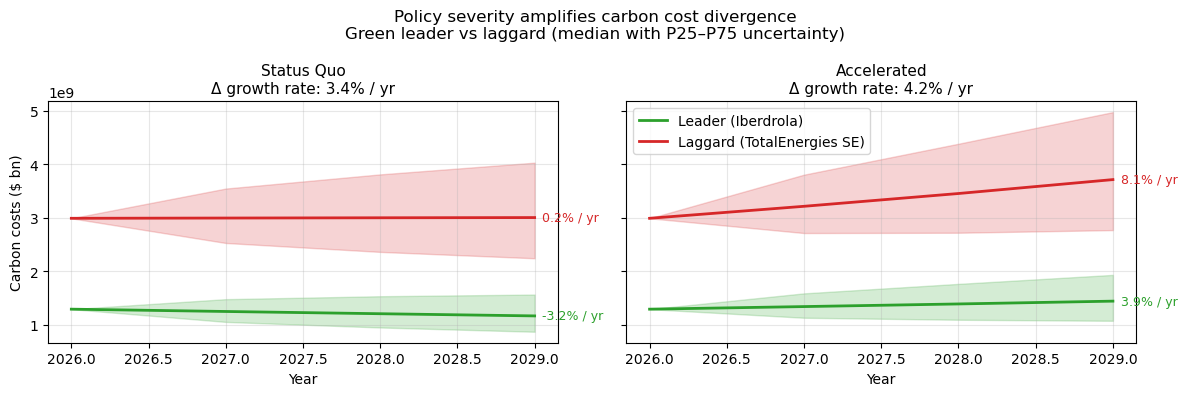

In [ ]:
# Green Leader & Laggard Exposure Comparison
# User selections
firms = {
    "Leader": "Iberdrola",
    "Laggard": "TotalEnergies SE"
}

regimes = ["status_quo", "accelerated"]
years = [2026, 2027, 2028, 2029]

colors = {
    "Leader": "tab:green",
    "Laggard": "tab:red"
}

# Filter data
df_plot = df_carbon_costs[
    (df_carbon_costs["Firm"].isin(firms.values())) &
    (df_carbon_costs["Year"].astype(int).isin(years)) &
    (df_carbon_costs["Percentile"].isin(["P25", "P50", "P75"])) &
    (df_carbon_costs["Regime"].isin(regimes))
]

df_plot["Year"] = df_plot["Year"].astype(int)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, regime in zip(axes, regimes):

    slopes_pct = {}   # store % slopes per regime

    for label, firm in firms.items():
        df_f = df_plot[
            (df_plot["Firm"] == firm) &
            (df_plot["Regime"] == regime)
        ]

        df_wide = df_f.pivot_table(
            index="Year",
            columns="Percentile",
            values="CarbonCost"
        ).sort_index()

        # Plot median
        ax.plot(
            df_wide.index,
            df_wide["P50"],
            label=f"{label} ({firm})",
            color=colors[label],
            linewidth=2
        )

        # Uncertainty band
        ax.fill_between(
            df_wide.index,
            df_wide["P25"],
            df_wide["P75"],
            color=colors[label],
            alpha=0.2
        )

        # ---- percentage slope calculation ----
        x = df_wide.index.values.astype(int)
        y = df_wide["P50"].values

        start_cost = y[0]
        end_cost = y[-1]
        n_years = x[-1] - x[0]

        slope_pct = ((end_cost - start_cost) / start_cost) / n_years * 100
        slopes_pct[label] = slope_pct

        # Annotate slope (%)
        ax.text(
            x[-1] + 0.05,
            y[-1],
            f"{slope_pct:.1f}% / yr",
            color=colors[label],
            fontsize=9,
            verticalalignment="center"
        )

    # ---- slope difference ----
    slope_diff = slopes_pct["Laggard"] - slopes_pct["Leader"]

    ax.set_title(
        f"{regime.replace('_', ' ').title()}\n"
        f"Δ growth rate: {slope_diff:.1f}% / yr",
        fontsize=11
    )

    ax.set_xlabel("Year")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Carbon costs ($ bn)")
axes[1].legend(loc="upper left")

fig.suptitle(
    "Policy severity amplifies carbon cost divergence\n"
    "Green leader vs laggard (median with P25–P75 uncertainty)",
    fontsize=12
)

plt.tight_layout()
plt.show()


c:\Users\POU\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


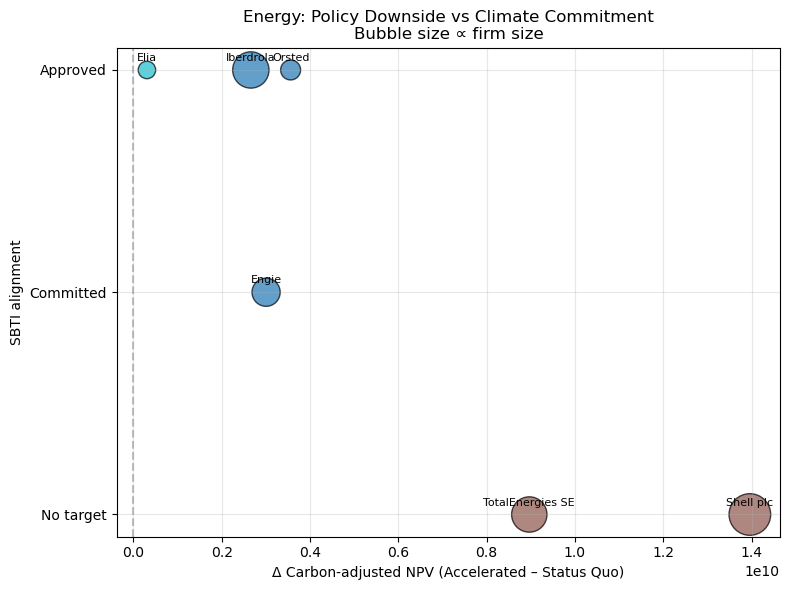

In [ ]:
# Sector Specific plot showcasing relation between SBTi Alignment and NPV
# Filter
chosen_sector = "Energy"    # choose : Life Sciences; Transport; Energy

df_ls = df_npvs[
    (df_npvs["Sector"] == chosen_sector) &
    (df_npvs["Percentile"] == "P50") &
    (df_npvs["Regime"].isin(["status_quo", "accelerated"]))
].copy()

# Pivot regimes into columns
df_pivot = df_ls.pivot_table(
    index=["Firm", "SBTI", "MarketCap"],
    columns="Regime",
    values="NPV"
).reset_index()

# ΔNPV: accelerated - status quo
df_pivot["Delta_NPV"] = (
    df_pivot["accelerated"] - df_pivot["status_quo"]
)

# Bublle Size : Firm Size
df_pivot["BubbleSize"] = (
    df_pivot["MarketCap"] / df_pivot["MarketCap"].max() * 800 + 100
)

from sklearn.cluster import KMeans

X = df_pivot[["Delta_NPV", "SBTI"]].values

kmeans = KMeans(n_clusters=3, random_state=42)
df_pivot["Cluster"] = kmeans.fit_predict(X)

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    df_pivot["Delta_NPV"],
    df_pivot["SBTI"],
    s=df_pivot["BubbleSize"],
    c=df_pivot["Cluster"],
    cmap="tab10",
    alpha=0.7,
    edgecolor="black"
)

# Firm labels (optional – keep sparse)
for _, row in df_pivot.iterrows():
    plt.text(
        row["Delta_NPV"],
        row["SBTI"] + 0.02,
        row["Firm"],
        fontsize=8,
        ha="center"
    )

plt.axvline(0, color="grey", linestyle="--", alpha=0.5)
plt.yticks([0, 0.5, 1.0], ["No target", "Committed", "Approved"])

plt.xlabel("Δ Carbon-adjusted NPV (Accelerated – Status Quo)")
plt.ylabel("SBTI alignment")
plt.title(
    f"{chosen_sector}: Policy Downside vs Climate Commitment\n"
    "Bubble size ∝ firm size"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
# Export data for PowerBI presentation

output_path = r"C:\Users\POU\OneDrive - Avertim\PowerBI_Data"

df_carbon_costs.to_excel(
    f"{output_path}\\carbon_costs.xlsx",
    index=False
)

df_npvs.to_excel(
    f"{output_path}\\npv_results.xlsx",
    index=False
)